In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

(CVXPY) Oct 28 12:39:51 AM: Encountered unexpected exception importing solver CBC:
ValueError('numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject')


In [2]:
T = 24 # Time periods
nb = 5 # Buses
nl = 4 # Lines
ng = 3 # Generators

In [3]:
# Generator-to-bus mapping
G = np.array([
    [1, 0, 0],
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [0, 0, 0]
])

# Line-to-bus mapping
K = np.array([
    [1, -1, 0, 0, 0],
    [1, 0, -1, 0, 0],
    [0, 0, 1, -1, 0],
    [0, 0, 0, 1, -1]
]).T

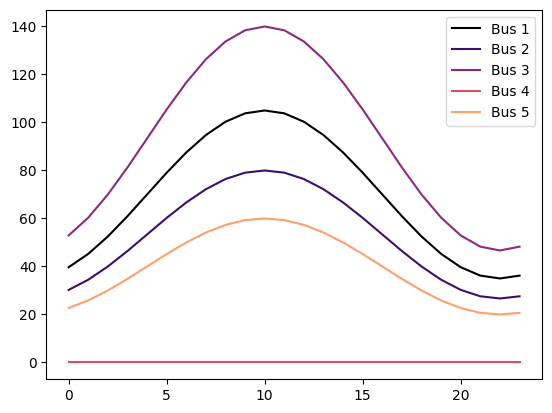

Total Peak Demand: 385 MW
Total Generation Capacity: 320 MW
Total Transmission Capacity: 325 MW


In [174]:
# Time
time = np.arange(24)

# Load
load_shape =  (np.sin(2 * np.pi * time / T - np.pi / 3) + 2) / 3
peak_demand = np.array([105, 80, 140, 0, 60])
load = (peak_demand * load_shape.reshape(-1, 1)).T

# Plot load shapes
cmap = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [cmap(i/5) for i in range(nb)]
for i in range(nb):
    plt.plot(time, load[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.show()

# Print total peak demand
print(f"Total Peak Demand: {peak_demand.sum()} MW")

# Generation
pmax = np.array([150, 95, 75])
print(f"Total Generation Capacity: {pmax.sum()} MW")

# Lines
fmax = np.array([100, 50, 100, 75])
print(f"Total Transmission Capacity: {fmax.sum()} MW")

# Rebound Demand
voll = 10 # $/kWh - baseline VoLL
gamma = 0.25 # Rebound demand multiplier

# Reshape data
pmax = np.tile(pmax[:, None], (1, T))
fmax = np.tile(fmax[:, None], (1, T))

In [194]:
# CVXPY Model

# Variables
p = cp.Variable((ng, T), nonneg=True)
f = cp.Variable((nl, T))
u = cp.Variable((nb, T), nonneg=True)
z = cp.Variable((nb, T), nonneg=True)

# Parameters
v = cp.Parameter((nb, T), nonneg=True) # Static VoLL
v.value = voll * np.ones((nb, T))
r = cp.Parameter((nb, T+1), nonneg=True) # Rebound demand
r.value = np.zeros((nb, T+1))
lam = cp.Parameter((nb, T+1), nonneg=True) # Costate
lam.value = np.zeros((nb, T+1))
d = cp.Parameter((nb, T), nonneg=True) # Demand
d.value = load

# Objectives
ue_costs = cp.sum(cp.multiply(v, u)) # Minimize unserved energy costs with static state variable
hamiltonian = ue_costs + cp.sum(cp.multiply(lam[:, 1:], cp.multiply(r[:, :-1], z) + gamma * cp.multiply(d + r[:, :-1], z)))

# Constraints
constraints = [
    G @ p + K @ f == d + r[:,:-1] - u,
    p <= pmax,
    f <= fmax,
    f >= -fmax,
    u == cp.multiply(d + r[:,:-1], z),
    z <= 1,
]

# Problem
problem = cp.Problem(cp.Minimize(hamiltonian), constraints)

# Solve
result = problem.solve("GUROBI")

print(result)
print(H_eval())
print(J_eval(z.value))

3383.5822289008065
3383.5822289008065
3775.8555785162384


/var/folders/dm/_r2wlmc97fl4btxdp2sb7st80000gn/T/ipykernel_8510/3557785889.py:37: UserWarning: You are solving a parameterized problem that is not DPP. Because the problem is not DPP, subsequent solves will not be faster than the first one. For more information, see the documentation on Disciplined Parametrized Programming, at https://www.cvxpy.org/tutorial/dpp/index.html
  result = problem.solve("GUROBI")


In [195]:
def r_eval(z):
    r = np.zeros((nb, T + 1))
    for t in range(T):
        r[:,t+1] = z[:,t] * r[:,t] + gamma * (d.value[:,t] + r[:,t]) * z[:,t]
    return r

def lam_eval(z):
    lam = np.zeros((nb, T + 1))
    for t in range(T)[::-1]:
        lam[:,t] = v.value[:,t] * z[:,t] + (1 + gamma) * z[:,t] * lam[:,t+1]
    return lam

def H_eval():
    # Hamiltonian eval
    # Call this after updating lam and x parameters
    return (hamiltonian).value

def J_eval(z):
    # Objective eval
    r = r_eval(z)
    u = (d.value + r[:,:-1]) * z
    return np.sum(v.value * u)

def state_residual(z, r):
    phi_z = r_eval(z)
    return np.linalg.norm(phi_z - r, ord=np.inf)

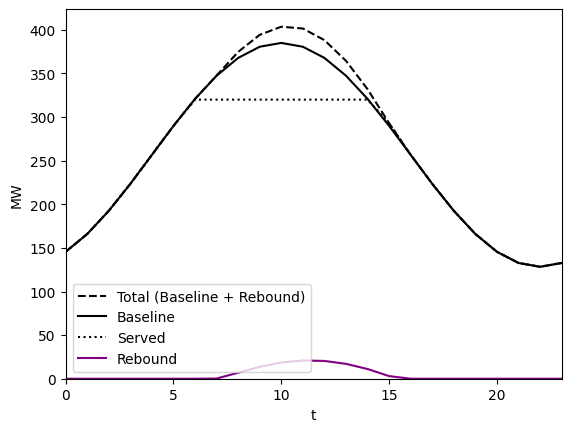

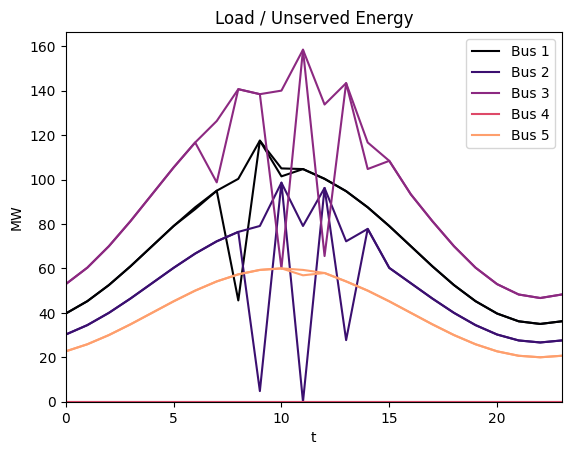

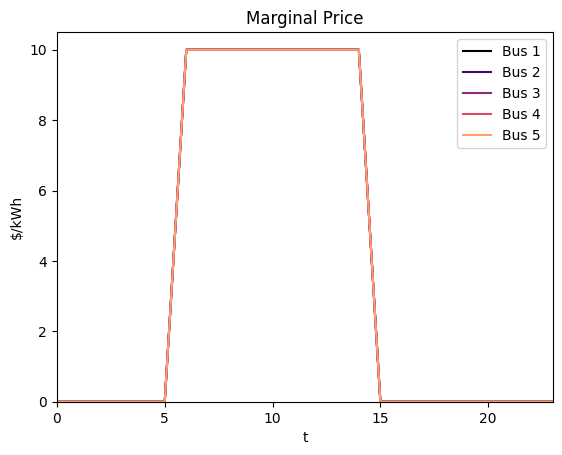

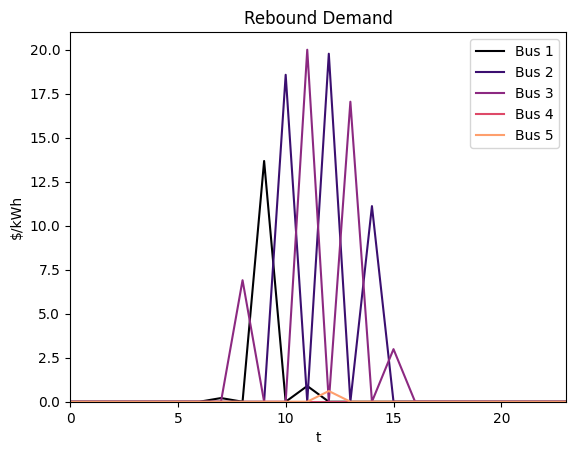

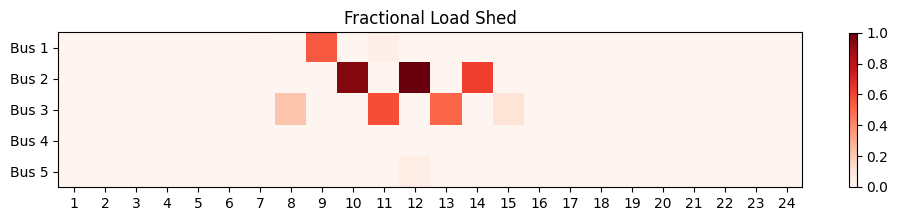

In [213]:
magma = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [magma(i/5) for i in range(nb)]

# Plot total unserved energy
rval = r.value
plt.plot(time, np.sum(load + rval[:,:-1], axis=0), color="black", linestyle="--", label="Total (Baseline + Rebound)")
plt.plot(time, np.sum(load, axis=0), color="black", label="Baseline")
plt.plot(time, np.sum(load + rval[:,:-1] - u.value, axis=0), linestyle=":", color="black", label="Served")
plt.plot(time, np.sum(rval[:,:-1], axis=0), color="purple", label="Rebound")
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.legend()
plt.show()

# Plot unserved energy by bus
plt.title("Load / Unserved Energy")
for i in range(nb):
    plt.plot(time, load[i,:] + rval[i,:-1], color=colors[i], label=labels[i])
    plt.plot(time, load[i,:] + rval[i,:-1] - u[i, :].value, color=colors[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot risk by bus
lmp = -constraints[0].dual_value
plt.title("Marginal Price")
for i in range(nb):
    plt.plot(time, lmp[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("$/kWh")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot stress level by bus
rval = r_eval(z.value)
plt.title("Rebound Demand")
for i in range(nb):
    plt.plot(time, rval[i,:-1], color=colors[i], label=labels[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("$/kWh")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot load shed fractions by bus
reds = plt.colormaps["Reds"]
plt.figure(figsize=(12, 10))
plt.title("Fractional Load Shed")
img = plt.imshow(z.value, cmap=reds)
plt.xticks(np.arange(T), [f"{t+1}" for t in np.arange(T)])
plt.yticks(np.arange(nb), [f"Bus {i+1}" for i in np.arange(nb)])
plt.colorbar(img, shrink=0.2)
plt.show()

In [212]:
# MSA Loop

# Solve model to initialize z_hat
z_hat = z.value

k = 0
cost_delta = np.inf
state_delta = np.inf
while k < 500 and cost_delta > 1e-6 and state_delta > 1e-2:
    print(k)

    # Update state trajectory
    r.value = r_eval(z_hat)
    
    # Update costate trajectory
    lam.value = lam_eval(z_hat)

    # Evaluate Hamiltonian
    Jk = J_eval(z_hat)
    Hk = H_eval()
    print(f"H(x{k+1}, u{k}, z{k+1}): {Hk:.2f} | J(z{k}) = {Jk:.2f}")

    # Solve model with Hamiltonian objective
    result = problem.solve("GUROBI")

    # Update z_hat
    A = 10
    a = A / (k + A)
    z_hat = (1 - a) * z_hat + a * z.value
    cost_delta = np.abs(J_eval(z_hat) - Jk) / Jk
    state_delta = state_residual(z.value, r.value)
    print(f"Step size: {a:.4f} | |J(z{k+1}) - J(z{k})|: {delta:.6f} | State Residual: {state_delta:.4f}")
    k += 1

0
H(x1, u0, z1): 4471.62 | J(z0) = 4471.62
Step size: 1.0000 | |J(z1) - J(z0)|: 0.000000 | State Residual: 52.4399
1
H(x2, u1, z2): 4543.81 | J(z1) = 4359.33
Step size: 0.9091 | |J(z2) - J(z1)|: 0.000000 | State Residual: 65.7698
2
H(x3, u2, z3): 4781.80 | J(z2) = 4486.16
Step size: 0.8333 | |J(z3) - J(z2)|: 0.000000 | State Residual: 70.2382
3
H(x4, u3, z4): 4815.49 | J(z3) = 4531.66
Step size: 0.7692 | |J(z4) - J(z3)|: 0.000000 | State Residual: 58.6113
4
H(x5, u4, z5): 4738.38 | J(z4) = 4601.47
Step size: 0.7143 | |J(z5) - J(z4)|: 0.000000 | State Residual: 40.6949
5
H(x6, u5, z6): 4614.64 | J(z5) = 4577.39
Step size: 0.6667 | |J(z6) - J(z5)|: 0.000000 | State Residual: 9.8490
6
H(x7, u6, z7): 4510.23 | J(z6) = 4526.99
Step size: 0.6250 | |J(z7) - J(z6)|: 0.000000 | State Residual: 3.2968
7
H(x8, u7, z8): 4484.42 | J(z7) = 4498.88
Step size: 0.5882 | |J(z8) - J(z7)|: 0.000000 | State Residual: 1.2751
8
H(x9, u8, z9): 4476.41 | J(z8) = 4485.16
Step size: 0.5556 | |J(z9) - J(z8)|: 0.0

In [44]:
import gurobipy as gp
from gurobipy import GRB
import numpy as np

def solve_rebound_opf(G, K, d, v, pmax, fmax, gamma, r0=None):
    """
    Solve the nonconvex rebound optimal control problem with Gurobi.

    Parameters
    ----------
    G : ndarray, shape (nb, ng)
        Generator-to-bus mapping matrix.
    K : ndarray, shape (nb, nl)
        Network flow-to-bus mapping matrix.
    d : ndarray, shape (nb, T)
        Demand.
    v : ndarray, shape (nb, T)
        Value of lost load.
    pmax : ndarray or scalar
        Generator capacity limits.
    fmax : ndarray or scalar
        Line flow limits.
    gamma : float
        Rebound parameter.
    r0 : ndarray, shape (nb,), optional
        Initial rebound state. Defaults to zero.

    Returns
    -------
    dict containing solution variables and objective value.
    """
    nb, T = d.shape
    ng = G.shape[1]
    nl = K.shape[1]

    if r0 is None:
        r0 = np.zeros(nb)

    m = gp.Model("rebound_opf")

    # Enable nonconvex quadratic constraints/objective.
    m.Params.NonConvex = 2

    # Variables
    p = m.addVars(ng, T, lb=0.0, ub=pmax, name="p")
    f = m.addVars(nl, T, lb=-np.asarray(fmax), ub=np.asarray(fmax), name="f")
    u = m.addVars(nb, T, lb=0.0, name="u")
    z = m.addVars(nb, T, lb=0.0, ub=1.0, name="z")
    r = m.addVars(nb, T + 1, lb=0.0, name="r")

    # Initial rebound state
    for i in range(nb):
        m.addConstr(r[i, 0] == float(r0[i]), name=f"initial_state_{i}")

    # Dynamics, power balance, and unserved demand
    for t in range(T):
        for i in range(nb):
            # r[i,t+1] = (1+gamma)*r[i,t]*z[i,t] + gamma*d[i,t]*z[i,t]
            m.addConstr(
                r[i, t+1]
                == (1 + gamma) * r[i, t] * z[i, t]
                + gamma * float(d[i, t]) * z[i, t],
                name=f"rebound_dynamics_{i}_{t}",
            )

            # u[i,t] = (d[i,t] + r[i,t])*z[i,t]
            m.addConstr(
                u[i, t] == (float(d[i, t]) + r[i, t]) * z[i, t],
                name=f"unserved_demand_{i}_{t}",
            )

            # 0 <= u[i,t] <= d[i,t] + r[i,t]
            m.addConstr(
                u[i, t] <= float(d[i, t]) + r[i, t],
                name=f"unserved_upper_bound_{i}_{t}",
            )

        # Nodal power balance: Gp + Kf = d + r - u
        for i in range(nb):
            m.addConstr(
                gp.quicksum(float(G[i, j]) * p[j, t] for j in range(ng))
                + gp.quicksum(float(K[i, ell]) * f[ell, t] for ell in range(nl))
                == float(d[i, t]) + r[i, t] - u[i, t],
                name=f"power_balance_{i}_{t}",
            )

    # Objective: total value of unserved energy
    m.setObjective(
        gp.quicksum(
            float(v[i, t]) * u[i, t]
            for i in range(nb)
            for t in range(T)
        ),
        GRB.MINIMIZE,
    )

    m.optimize()

    if m.SolCount == 0:
        return {"status": m.Status, "objective": None}

    p_sol = np.array([[p[j, t].X for t in range(T)] for j in range(ng)])
    f_sol = np.array([[f[j, t].X for t in range(T)] for j in range(nl)])
    u_sol = np.array([[u[i, t].X for t in range(T)] for i in range(nb)])
    z_sol = np.array([[z[i, t].X for t in range(T)] for i in range(nb)])
    r_sol = np.array([[r[i, t].X for t in range(T + 1)] for i in range(nb)])

    return {
        "status": m.Status,
        "objective": m.ObjVal,
        "p": p_sol,
        "f": f_sol,
        "u": u_sol,
        "z": z_sol,
        "r": r_sol,
        "model": m,
    }

In [46]:
sol = solve_rebound_opf(G, K, d.value, v.value, pmax, fmax, gamma)

Set parameter NonConvex to value 2
Gurobi Optimizer version 13.0.0 build v13.0.0rc1 (mac64[arm] - Darwin 24.3.0 24D70)

CPU model: Apple M3
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
NonConvex  2

Academic license 2819194 - for non-commercial use only - registered to ch___@berkeley.edu
Optimize a model with 245 rows, 533 columns and 749 nonzeros (Min)
Model fingerprint: 0xdb41d412
Model has 120 linear objective coefficients
Model has 240 quadratic constraints
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+02]
  Objective range  [1e+01, 1e+01]
  Bounds range     [1e+00, 2e+02]
  RHS range        [2e+01, 1e+02]
Presolve removed 35 rows and 56 columns

Continuous model is non-convex -- solving as a MIP

Presolve removed 65 rows and 196 columns
Presolve time: 0.01s
Presolved: 548 rows, 338 columns, 1580 nonzeros
Presolved model has 92 bilinear constraint(s)
V